## Glimpse on Neglected Tropical Diseases through global stats

Content

-Intro

-Fetch data

-Exploration
- Geographical angle

-Perspectives
-Ref? 

In [ ]:
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches


### Fetching GEO data

In [200]:
# Fetch data
geo_raw = "NTD_geo_data_2010to24.csv"
df_geo_raw = pd.read_csv(geo_raw)

In [54]:
df_geo_raw.info() # all col with 2921 entries no Nan :) 
df_geo_raw.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2921 entries, 0 to 2920
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   IND_ID                  2921 non-null   object 
 1   IND_CODE                2921 non-null   object 
 2   IND_UUID                2921 non-null   object 
 3   IND_PER_CODE            2921 non-null   object 
 4   DIM_TIME                2921 non-null   int64  
 5   DIM_TIME_TYPE           2921 non-null   object 
 6   DIM_GEO_CODE_M49        2921 non-null   int64  
 7   DIM_GEO_CODE_TYPE       2921 non-null   object 
 8   DIM_PUBLISH_STATE_CODE  2921 non-null   object 
 9   IND_NAME                2921 non-null   object 
 10  GEO_NAME_SHORT          2921 non-null   object 
 11  COUNT_N                 2921 non-null   float64
dtypes: float64(1), int64(2), object(9)
memory usage: 274.0+ KB


,IND_ID,IND_CODE,IND_UUID,IND_PER_CODE,DIM_TIME,DIM_TIME_TYPE,DIM_GEO_CODE_M49,DIM_GEO_CODE_TYPE,DIM_PUBLISH_STATE_CODE,IND_NAME,GEO_NAME_SHORT,COUNT_N
0,2D6FBE4SDGNTDTREATMENT,SDGNTDTREATMENT,2D6FBE4,SDGNTDTREATMENT,2010,YEAR,64,COUNTRY,PUBLISHED,People requiring interventions against Neglect...,Bhutan,69529.0
1,2D6FBE4SDGNTDTREATMENT,SDGNTDTREATMENT,2D6FBE4,SDGNTDTREATMENT,2010,YEAR,68,COUNTRY,PUBLISHED,People requiring interventions against Neglect...,Bolivia (Plurinational State of),3340916.0
2,2D6FBE4SDGNTDTREATMENT,SDGNTDTREATMENT,2D6FBE4,SDGNTDTREATMENT,2010,YEAR,70,COUNTRY,PUBLISHED,People requiring interventions against Neglect...,Bosnia and Herzegovina,1.0
3,2D6FBE4SDGNTDTREATMENT,SDGNTDTREATMENT,2D6FBE4,SDGNTDTREATMENT,2010,YEAR,72,COUNTRY,PUBLISHED,People requiring interventions against Neglect...,Botswana,264669.0
4,2D6FBE4SDGNTDTREATMENT,SDGNTDTREATMENT,2D6FBE4,SDGNTDTREATMENT,2010,YEAR,76,COUNTRY,PUBLISHED,People requiring interventions against Neglect...,Brazil,27000000.0


Columns with only 1 data value throughout are not kept.

In [201]:
# not keeping col with only 1 value throughout 
lo_col_keep_geo = ['IND_ID',
                    'DIM_TIME',
                    'DIM_GEO_CODE_M49',
                    'DIM_GEO_CODE_TYPE',
                    'GEO_NAME_SHORT',
                    'COUNT_N']

df_geo = df_geo_raw[lo_col_keep_geo]

dim_geo_mask = df_geo["DIM_GEO_CODE_TYPE"] == "COUNTRY"

df_geo = df_geo[dim_geo_mask]
#shape (2716,6)
df_geo.head()

,IND_ID,DIM_TIME,DIM_GEO_CODE_M49,DIM_GEO_CODE_TYPE,GEO_NAME_SHORT,COUNT_N
0,2D6FBE4SDGNTDTREATMENT,2010,64,COUNTRY,Bhutan,69529.0
1,2D6FBE4SDGNTDTREATMENT,2010,68,COUNTRY,Bolivia (Plurinational State of),3340916.0
2,2D6FBE4SDGNTDTREATMENT,2010,70,COUNTRY,Bosnia and Herzegovina,1.0
3,2D6FBE4SDGNTDTREATMENT,2010,72,COUNTRY,Botswana,264669.0
4,2D6FBE4SDGNTDTREATMENT,2010,76,COUNTRY,Brazil,27000000.0


In [5]:
df_geo_raw.DIM_TIME.unique()

array([2010, 2013, 2012, 2011, 2016, 2017, 2020, 2023, 2019, 2015, 2022,
       2018, 2021, 2014])

Getting total number of interventions per year.

In [202]:
df_geo_gr_year = df_geo.groupby("DIM_TIME").sum()
df_geo_gr_year.head()

,IND_ID,DIM_GEO_CODE_M49,DIM_GEO_CODE_TYPE,GEO_NAME_SHORT,COUNT_N
DIM_TIME,,,,,
2010,2D6FBE4SDGNTDTREATMENT2D6FBE4SDGNTDTREATMENT2D...,83939,COUNTRYCOUNTRYCOUNTRYCOUNTRYCOUNTRYCOUNTRYCOUN...,BhutanBolivia (Plurinational State of)Bosnia a...,2.153978e+09
2011,2D6FBE4SDGNTDTREATMENT2D6FBE4SDGNTDTREATMENT2D...,83939,COUNTRYCOUNTRYCOUNTRYCOUNTRYCOUNTRYCOUNTRYCOUN...,Saudi ArabiaSenegalSerbiaSeychellesSierra Leon...,2.136595e+09
2012,2D6FBE4SDGNTDTREATMENT2D6FBE4SDGNTDTREATMENT2D...,83939,COUNTRYCOUNTRYCOUNTRYCOUNTRYCOUNTRYCOUNTRYCOUN...,NauruNepalNetherlands (Kingdom of the)VanuatuN...,2.081831e+09
2013,2D6FBE4SDGNTDTREATMENT2D6FBE4SDGNTDTREATMENT2D...,83939,COUNTRYCOUNTRYCOUNTRYCOUNTRYCOUNTRYCOUNTRYCOUN...,AzerbaijanArgentinaAustraliaAustriaBahamasBahr...,1.982020e+09
2014,2D6FBE4SDGNTDTREATMENT2D6FBE4SDGNTDTREATMENT2D...,83939,COUNTRYCOUNTRYCOUNTRYCOUNTRYCOUNTRYCOUNTRYCOUN...,Guinea-BissauTimor-LesteQatarRomaniaRussian Fe...,1.873900e+09


In [ ]:
#from matplotlib.font_manager import get_font_names
#list(sorted(get_font_names()))

['Abyssinica SIL',
 'Ani',
 'AnjaliOldLipi',
 'C059',
 'Chandas',
 'Chilanka',
 'D050000L',
 'DejaVu Math TeX Gyre',
 'DejaVu Sans',
 'DejaVu Sans Condensed',
 'DejaVu Sans Display',
 'DejaVu Sans Light',
 'DejaVu Sans Mono',
 'DejaVu Serif',
 'DejaVu Serif Condensed',
 'DejaVu Serif Display',
 'Dhurjati',
 'Droid Sans Fallback',
 'Dyuthi',
 'FreeMono',
 'FreeSans',
 'FreeSerif',
 'GLYPHICONS Halflings',
 'Gargi',
 'Garuda',
 'Gayathri',
 'Gayathri Thin',
 'Gidugu',
 'Gubbi',
 'Gurajada',
 'Jamrul',
 'KacstArt',
 'KacstBook',
 'KacstDecorative',
 'KacstDigital',
 'KacstFarsi',
 'KacstLetter',
 'KacstNaskh',
 'KacstOffice',
 'KacstOne',
 'KacstPen',
 'KacstPoster',
 'KacstQurn',
 'KacstScreen',
 'KacstTitle',
 'KacstTitleL',
 'Kalapi',
 'Kalimati',
 'Karumbi',
 'Keraleeyam',
 'Khmer OS',
 'Khmer OS System',
 'Kinnari',
 'LKLUG',
 'LakkiReddy',
 'Laksaman',
 'Last Resort High-Efficiency',
 'Liberation Mono',
 'Liberation Sans',
 'Liberation Sans Narrow',
 'Liberation Serif',
 'Likhan',
 

### Line plot of all interventions

findfont: Failed to find font weight normal for DejaVu Sans Condensed, now using 380.
findfont: Failed to find font weight normal for DejaVu Sans Condensed, now using 380.


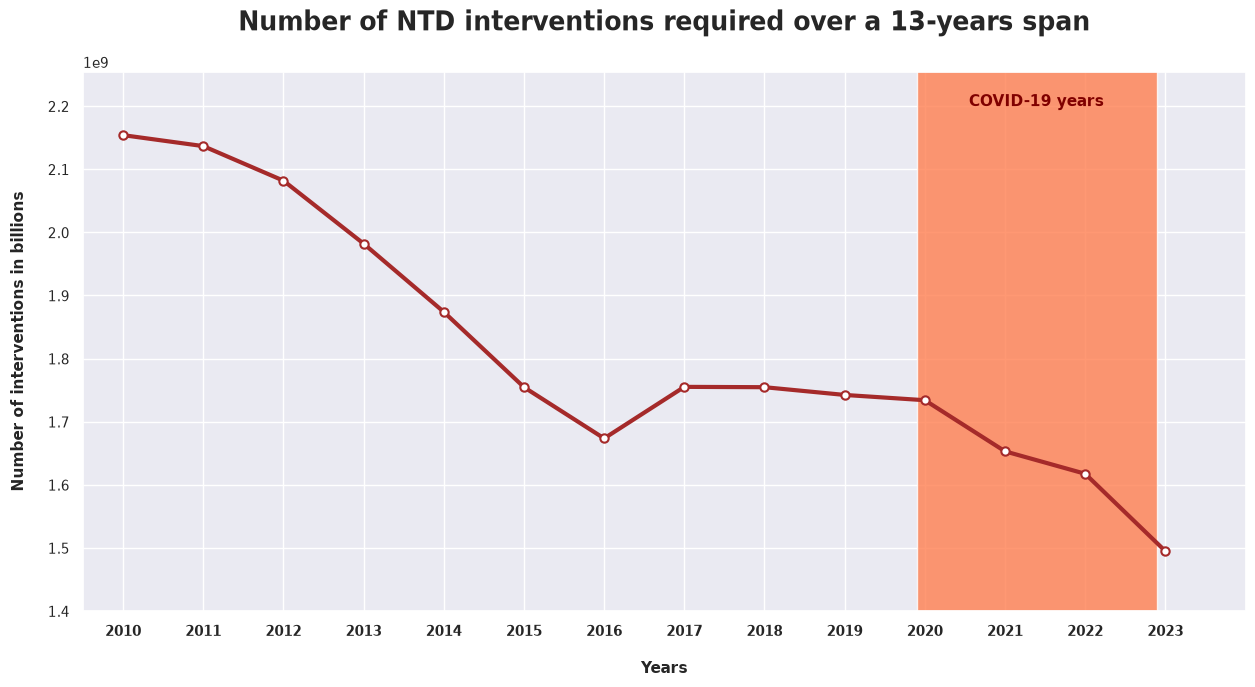

In [203]:
#--------------------------------------------------
#    Defining x y limits + Plotting
#--------------------------------------------------
year_one = int(df_geo.DIM_TIME.sort_values().unique()[0])
year_end = int(df_geo.DIM_TIME.sort_values().unique()[-1])
lo_xtick = list(df_geo_gr_year.index)

y_one = int(df_geo_gr_year.COUNT_N.min())
y_end = int(df_geo_gr_year.COUNT_N.max())

# Setting theme and Initializing plot
sns.set_theme(font="DejaVu Sans Condensed", palette="colorblind") # is palette useful here ???? 
fig, axx = plt.subplots(figsize=(15,7))

# Plotting
sns.lineplot(x=df_geo_gr_year.index, y=df_geo_gr_year.COUNT_N,
             color = "brown", linewidth = 3,
             marker="o", mfc="white",
             mec = "brown",mew = 1.5)

#--------------------------------------------------
#    Plot labelling
#--------------------------------------------------
interventions_lab = "Number of interventions in billions"

plt.xlabel("Years",
            weight="bold", labelpad=15) #NOTE perso labelpad : ajuster esapce entre axe et légende !!

plt.ylabel(interventions_lab,
            weight="bold", labelpad=15)

plt.title("Number of NTD interventions required over a 13-years span", 
           weight="bold", fontsize = 20, pad=30 )

#-------------------------------------------------
#   Adjusting plot axis                          
#-------------------------------------------------
plt.xlim(year_one -0.5, year_end+1)
plt.ylim(1.4e+09, y_end + (1.0e+8))

plt.xticks(lo_xtick, weight = "bold")
#plt.yticks(weight = "bold", color = "brown")

#--------------------------------------------------
#   Adding rect to highlighting COVID years 
#--------------------------------------------------

left, bottom, width, height = (2019.9, 1.4e+09, 3, 2.3e+09)
rect = mpatches.Rectangle((left, bottom), width, height,
                          facecolor = "coral", alpha = 0.8) #translucent fill with alpha :)
ax = plt.gca()
ax.add_patch(rect)

# Adding text to patch
ax.text(left + 0.65, 
        height - 1e+08,
        "COVID-19 years", weight="bold",
        color = "maroon" )

#--------------------------------------------------

# Setting borders around plot to transparent :)))
fig.patch.set_alpha(0) 
# ça ne voit pas ici mais dans marp ça marche !! :) 


plt.savefig("./img/NTDinterventions_years.png")#, transparent=True)
plt.show();

The number of interventions seem to have decreased throughout the 13-years span, with a marked drop in 2016 and through the Covid-19 years. The latter shouldn't be associated to a decrease of NTD cases as such but it could rather be a resulting effect lives lost due to the pandemic.

In [13]:
df_geo.DIM_GEO_CODE_M49.nunique() == df_geo.GEO_NAME_SHORT.nunique()

True

### h Barplot for all 13 years of top 10 countries
---

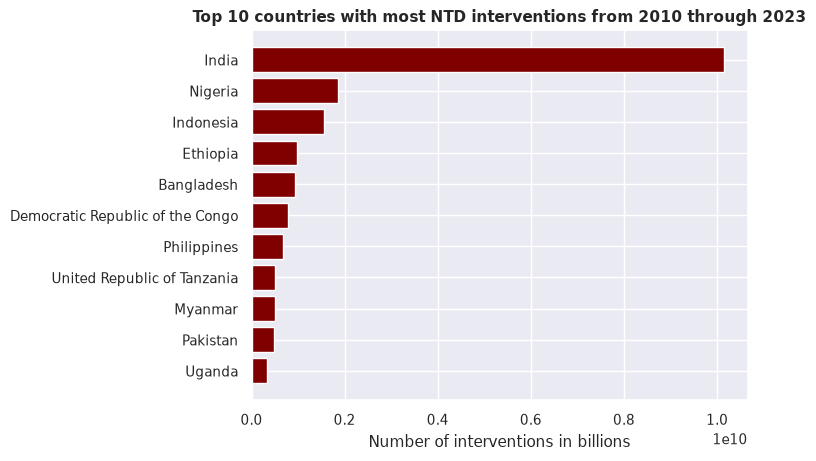

In [ ]:
# interventions totales par pays sur 13 ans

fig, ax = plt.subplots()


df_geo.GEO_NAME_SHORT.nunique() # 194 countries
df_geo_gr_name = df_geo[["GEO_NAME_SHORT", "COUNT_N"]]
df_geo_gr_name = df_geo_gr_name.groupby("GEO_NAME_SHORT").sum().sort_values("COUNT_N", ascending=True).iloc[-11:,:]

bars = ax.barh(df_geo_gr_name.index, df_geo_gr_name.COUNT_N , color='maroon')

ax.set_title("Top 10 countries with most NTD interventions from 2010 through 2023", weight= "bold")
ax.set_xlabel(interventions_lab);

#--------------------------------------------------

# Setting borders around plot to transparent :)))
fig.patch.set_alpha(0) 
# ça ne voit pas ici mais dans marp ça marche !! :) 


plt.savefig("./img/Top10_countries_NTDs_barplot.png")#, transparent=True)
plt.show();


The barplot shows the distribution of the total number of interventions required from 2010 to 2023 in the top 10 countries. It should be noted that the number of cases here have not been 'reduced' to a ratio of each country's population.
Next : "pondérer" on nation's population!

In [53]:
#df_geo_gr_name = df_geo[["GEO_NAME_SHORT", "COUNT_N"]]

print(df_geo_gr_name.shape)
df_geo_gr_name.head(10)
#m = df_geo_gr_name[["COUNT_N"]] == 1
#df_geo_gr_name[m].value_counts()


(11, 1)


,COUNT_N
GEO_NAME_SHORT,
Uganda,3.374911e+08
Pakistan,4.889508e+08
Myanmar,4.955106e+08
United Republic of Tanzania,4.999512e+08
Philippines,6.759182e+08
Democratic Republic of the Congo,7.854268e+08
Bangladesh,9.247352e+08
Ethiopia,9.735808e+08
Indonesia,1.550447e+09


In [ ]:
df_geo_gr_name.index

Index(['India', 'Nigeria', 'Indonesia', 'Ethiopia', 'Bangladesh',
       'Democratic Republic of the Congo', 'Philippines',
       'United Republic of Tanzania', 'Myanmar', 'Pakistan', 'Uganda'],
      dtype='object', name='GEO_NAME_SHORT')

In [ ]:
df_geo_gr_name.sort_values("COUNT_N", ascending=False)

,COUNT_N
GEO_NAME_SHORT,
India,1.014482e+10
Nigeria,1.863471e+09
Indonesia,1.550447e+09
Ethiopia,9.735808e+08
Bangladesh,9.247352e+08
Democratic Republic of the Congo,7.854268e+08
Philippines,6.759182e+08
United Republic of Tanzania,4.999512e+08
Myanmar,4.955106e+08


['India',
 'Nigeria',
 'Indonesia',
 'Ethiopia',
 'Bangladesh',
 'Democratic Republic of the Congo',
 'Philippines',
 'United Republic of Tanzania',
 'Myanmar',
 'Pakistan',
 'Uganda']

### h Barplot for all 2010, COVID-19 years, 2023 of top 10 countries of top 10 countries ?

---

In [206]:

# interventions totales par pays sur 6 ans (début, fin et années covid)
lo_years = [year_one, 2020, 2021, 2022, year_end]
lo_countries = list(df_geo_gr_name.sort_values("COUNT_N", ascending=False).index)


df_geo.GEO_NAME_SHORT.nunique() # 194 countries
df_geo_gr_6years = df_geo[["GEO_NAME_SHORT", "DIM_TIME", "COUNT_N"]]

m_years = df_geo_gr_6years["DIM_TIME"].isin(lo_years)
df_geo_gr_6years = df_geo[m_years]

#selecting only top10 countries
m_countries = df_geo_gr_6years["GEO_NAME_SHORT"].isin(lo_countries)
df_geo_gr_6years = df_geo_gr_6years[m_countries]

df_geo_gr_6years.sort_values(by= ["GEO_NAME_SHORT","COUNT_N"],ascending = [False,False], inplace=True)

#df_geo_gr_6years.groupby(by=["GEO_NAME_SHORT", "DIM_TIME"]).sum().sort_index()
#df_geo_gr_6years.drop(["IND_ID", "DIM_GEO_CODE_TYPE"], axis=1, inplace=True)

In [60]:
df_geo_gr_6years.head()

,IND_ID,DIM_TIME,DIM_GEO_CODE_M49,DIM_GEO_CODE_TYPE,GEO_NAME_SHORT,COUNT_N
522,2D6FBE4SDGNTDTREATMENT,2010,834,COUNTRY,United Republic of Tanzania,43656348.0
2906,2D6FBE4SDGNTDTREATMENT,2023,834,COUNTRY,United Republic of Tanzania,36039903.0
1571,2D6FBE4SDGNTDTREATMENT,2022,834,COUNTRY,United Republic of Tanzania,34835231.0
2060,2D6FBE4SDGNTDTREATMENT,2021,834,COUNTRY,United Republic of Tanzania,32876354.0
2549,2D6FBE4SDGNTDTREATMENT,2020,834,COUNTRY,United Republic of Tanzania,29038890.0


In [47]:
list(df_geo_gr_name.index)

['Uganda',
 'Pakistan',
 'Myanmar',
 'United Republic of Tanzania',
 'Philippines',
 'Democratic Republic of the Congo',
 'Bangladesh',
 'Ethiopia',
 'Indonesia',
 'Nigeria',
 'India']

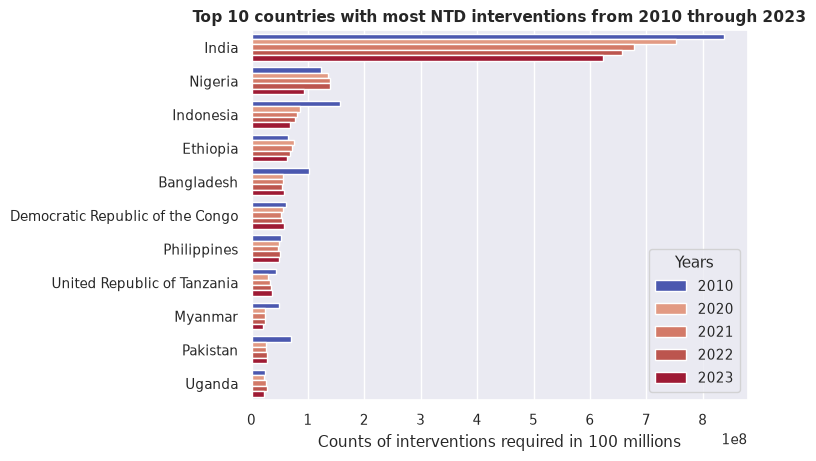

In [207]:
#sns.countplot(hue=df_geo_gr_6years["GEO_NAME_SHORT"], x=df_geo_gr_6years["COUNT_N"], color="red")

ax = sns.barplot(y = "GEO_NAME_SHORT",
            x = "COUNT_N",
            hue = "DIM_TIME",
            data = df_geo_gr_6years,
            order = lo_countries,
            palette = "coolwarm")



ax.set_title("Top 10 countries with most NTD interventions from 2010 through 2023", weight= "bold")
ax.set(xlabel = "Counts of interventions required in 100 millions", ylabel="")
plt.legend(title = "Years")
#plt.barh(data=df_geo_gr_6years, x="GEO_NAME_SHORT", y="COUNT_N", hue="DIM_TIME")

#--------------------------------------------------

# Setting borders around plot to transparent :)))
fig.patch.set_alpha(0) 
# ça ne voit pas ici mais dans marp ça marche !! :) 


plt.savefig("./img/Top10_countries_NTDS.png")#, transparent=True)
plt.show();

### bar plot in 2 ways (increase / decrease) of interventions
#### PONDERER sur les pop?? ou utiliser % de la pop ?
---

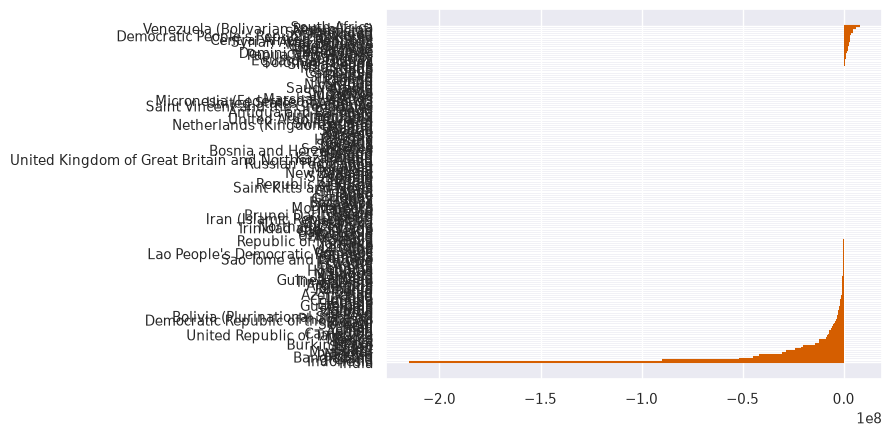

In [62]:
m_first_last_year = df_geo["DIM_TIME"].isin([year_one, year_end])
df_geo_yrOne_yrEnd = df_geo[m_first_last_year].drop(columns=["IND_ID", "DIM_GEO_CODE_TYPE", "DIM_GEO_CODE_M49"])

df_pivoted = df_geo_yrOne_yrEnd.pivot(index = "GEO_NAME_SHORT" ,columns="DIM_TIME", values="COUNT_N")

df_pivoted["diff"] = df_pivoted[2023] - df_pivoted[2010]

df_pivoted.sort_values("diff", ascending=True, inplace=True)
df_pivoted.head()
df_pivoted = df_pivoted[df_pivoted["diff"] != 0]

plt.hlines(y=df_pivoted.index,
            xmin=0,
            xmax=df_pivoted["diff"], color="r")


#### PLOT GEO

In [ ]:
#%pip install geodatasets

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [geodatasets] [geodatasets]
Note: you may need to restart the kernel to use updated packages.


In [ ]:
import geopandas as gpd
import geodatasets

In [16]:
# 2. Charger la carte du monde statique (Natural Earth)
url_map = "https://naciscdn.org"
world = gpd.read_file(geodatasets.get_path("naturalearth"))
#world = world[world["ADM0_A3"] != "ATA"]  # Retirer l'Antarctique pour une carte plus propre

years = [2010, 2020, 2021, 2024]

lo_titles = ["2010 (1st collection year)",
             "2020 (COVID year1)",
             "2021 (COVID year2)",
             "2024 (Last collection year)"]

fig, axes = plt.subplots(2,2, figsize=(16,9))
axes = axes.flatten()

# Scale of common colour to compare the 4 maps
# Échelle de couleur commune pour comparer honnêtement les 4 cartes
vmax = df_geo[df_geo["DIM_TIME"].isin(years)].max()

for i, year in enumerate(years):
    df_an = df_geo[df_geo["DIM_TIME"] == year]
    carte_an = world.merge(df_an, left_on="NAME", right_on="GEO_NAME_SHORT", how="left")

    carte_an.plot(
        column=year,
        ax=axes[i],
        cmap="YlOrRd",
        vmin=0,
        vmax=vmax,
        legend=(i == 3),  # Affiche la légende une seule fois sur la dernière carte
        legend_kwds={"label": "People requiring intervention", "shrink": 0.6},
        missing_kwds={"color": "#eeeeee", "edgecolor": "#cccccc", "label": "Missing data"},
    )
    axes[i].set_title(titres[i], fontsize=13, fontweight="bold")
    axes[i].axis("off")  # Supprime les axes latitude/longitude

plt.suptitle(
    "Global evolution of NTDs : 2010 vs COVID years (2020–2021) vs 2024",
    fontsize=16,
    fontweight="bold",
    y=0.98,
)
plt.tight_layout()
plt.savefig("statitic_maps_ntds_2010_2024.png", dpi=300, bbox_inches="tight")
plt.show()


ValueError: No matching item found for the query 'naturalearth'.

In [26]:
list(geodatasets.data.flatten().keys())

['abs.australia',
 'abs.australia_states_territories',
 'eea.large_rivers',
 'geoda.airbnb',
 'geoda.atlanta',
 'geoda.cars',
 'geoda.ceara_zika',
 'geoda.charleston1',
 'geoda.charleston2',
 'geoda.chicago_carjackings',
 'geoda.chicago_cca',
 'geoda.chicago_commpop',
 'geoda.chicago_health',
 'geoda.chicago_sdoh',
 'geoda.chile_labor',
 'geoda.cincinnati',
 'geoda.cleveland',
 'geoda.denver',
 'geoda.grid100',
 'geoda.groceries',
 'geoda.guerry',
 'geoda.health',
 'geoda.health_indicators',
 'geoda.hickory1',
 'geoda.hickory2',
 'geoda.home_sales',
 'geoda.houston',
 'geoda.italy_banks',
 'geoda.juvenile',
 'geoda.lansing1',
 'geoda.lansing2',
 'geoda.lasrosas',
 'geoda.liquor_stores',
 'geoda.malaria',
 'geoda.milwaukee1',
 'geoda.milwaukee2',
 'geoda.natregimes',
 'geoda.ncovr',
 'geoda.ndvi',
 'geoda.nepal',
 'geoda.nyc',
 'geoda.nyc_earnings',
 'geoda.nyc_education',
 'geoda.nyc_neighborhoods',
 'geoda.oaxaca',
 'geoda.orlando1',
 'geoda.orlando2',
 'geoda.oz9799',
 'geoda.phoenix

In [52]:
url_map = "https://naciscdn.org/naturalearth/110m/cultural/ne_110m_admin_0_countries.zip"
world = gpd.read_file(url_map)

list(sorted(world.NAME_LONG))

['Afghanistan',
 'Albania',
 'Algeria',
 'Angola',
 'Antarctica',
 'Argentina',
 'Armenia',
 'Australia',
 'Austria',
 'Azerbaijan',
 'Bahamas',
 'Bangladesh',
 'Belarus',
 'Belgium',
 'Belize',
 'Benin',
 'Bhutan',
 'Bolivia',
 'Bosnia and Herzegovina',
 'Botswana',
 'Brazil',
 'Brunei Darussalam',
 'Bulgaria',
 'Burkina Faso',
 'Burundi',
 'Cambodia',
 'Cameroon',
 'Canada',
 'Central African Republic',
 'Chad',
 'Chile',
 'China',
 'Colombia',
 'Costa Rica',
 'Croatia',
 'Cuba',
 'Cyprus',
 'Czech Republic',
 "Côte d'Ivoire",
 'Dem. Rep. Korea',
 'Democratic Republic of the Congo',
 'Denmark',
 'Djibouti',
 'Dominican Republic',
 'Ecuador',
 'Egypt',
 'El Salvador',
 'Equatorial Guinea',
 'Eritrea',
 'Estonia',
 'Ethiopia',
 'Falkland Islands / Malvinas',
 'Fiji',
 'Finland',
 'France',
 'French Southern and Antarctic Lands',
 'Gabon',
 'Georgia',
 'Germany',
 'Ghana',
 'Greece',
 'Greenland',
 'Guatemala',
 'Guinea',
 'Guinea-Bissau',
 'Guyana',
 'Haiti',
 'Honduras',
 'Hungary',
 

In [48]:
sorted(df_geo.GEO_NAME_SHORT.unique())

['Afghanistan',
 'Albania',
 'Algeria',
 'Andorra',
 'Angola',
 'Antigua and Barbuda',
 'Argentina',
 'Armenia',
 'Australia',
 'Austria',
 'Azerbaijan',
 'Bahamas',
 'Bahrain',
 'Bangladesh',
 'Barbados',
 'Belarus',
 'Belgium',
 'Belize',
 'Benin',
 'Bhutan',
 'Bolivia (Plurinational State of)',
 'Bosnia and Herzegovina',
 'Botswana',
 'Brazil',
 'Brunei Darussalam',
 'Bulgaria',
 'Burkina Faso',
 'Burundi',
 'Cabo Verde',
 'Cambodia',
 'Cameroon',
 'Canada',
 'Central African Republic',
 'Chad',
 'Chile',
 'China',
 'Colombia',
 'Comoros',
 'Congo',
 'Cook Islands',
 'Costa Rica',
 'Croatia',
 'Cuba',
 'Cyprus',
 'Czechia',
 "Côte d'Ivoire",
 "Democratic People's Republic of Korea",
 'Democratic Republic of the Congo',
 'Denmark',
 'Djibouti',
 'Dominica',
 'Dominican Republic',
 'Ecuador',
 'Egypt',
 'El Salvador',
 'Equatorial Guinea',
 'Eritrea',
 'Estonia',
 'Eswatini',
 'Ethiopia',
 'Fiji',
 'Finland',
 'France',
 'Gabon',
 'Gambia',
 'Georgia',
 'Germany',
 'Ghana',
 'Greece',

## NTD - diseases, pathogens

In [6]:
df_ntd_dm = pd.read_csv("NTD_disease_microO.csv") 
df_ntd_dm

,Disease_NTD,Pathogen_Class,Causative_Microorganisms
0,Buruli ulcer,Bacteria,Mycobacterium ulcerans
1,Chagas disease,Protozoa,Trypanosoma cruzi
2,Chikungunya,Virus,Chikungunya virus
3,Chromoblastomycosis and deep mycoses,Fungi,Fonsecaea pedrosoi - Cladophialophora carrioni...
4,Dengue,Virus,Dengue virus
5,Dracunculiasis (Guinea-worm),Helminth,Dracunculus medinensis
6,Echinococcosis,Helminth,Echinococcus granulosus - Echinococcus multilo...
7,Foodborne trematodiases,Helminth,Clonorchis sinensis - Opisthorchis spp. - Fasc...
8,Human African trypanosomiasis,Protozoa,Trypanosoma brucei gambiense - Trypanosoma bru...
9,Leishmaniasis,Protozoa,Leishmania donovani - Leishmania major - Leish...


In [7]:
# replacing the "/" with "-"
df_ntd_dm.iloc[12].Pathogen_Class = df_ntd_dm.iloc[12].Pathogen_Class.replace(" / ", "-")
df_ntd_dm.iloc[12].Pathogen_Class

'Bacteria-Fungi'

In [12]:
df_ntd_dm[["Disease_NTD"]][0:10]

,Disease_NTD
0,Buruli ulcer
1,Chagas disease
2,Chikungunya
3,Chromoblastomycosis and deep mycoses
4,Dengue
5,Dracunculiasis (Guinea-worm)
6,Echinococcosis
7,Foodborne trematodiases
8,Human African trypanosomiasis
9,Leishmaniasis


In [24]:
df_ntd_dm.Pathogen_Class.value_counts()

Pathogen_Class
Helminth            8
Bacteria            5
Protozoa            3
Virus               3
Fungi               1
Bacteria / Fungi    1
Ectoparasite        1
Name: count, dtype: int64

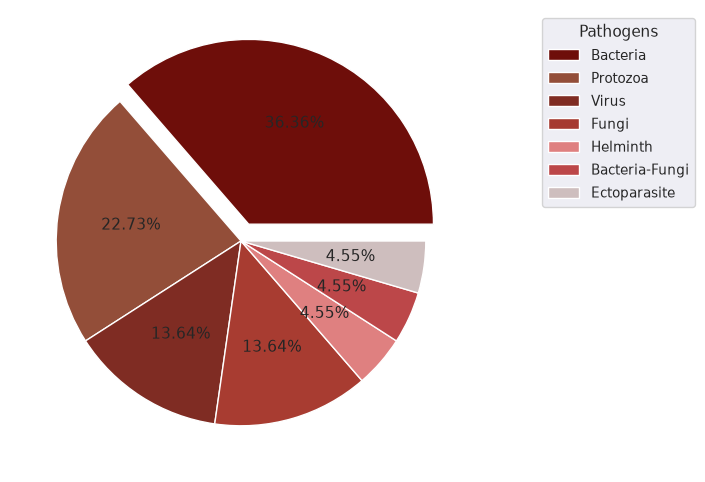

In [208]:
# pie chart NTD pathogens
# "Cinnamon Wine Harvest" inspired palette as seen in coolors :)

palette_col = ["#6E0E0A", "#934E39", "#7F2C23", "#9E2518E3", "#DF8080", "#BC4749", "#CEBEBE"]
explode_1st = [0.1, 0, 0, 0, 0, 0, 0]

fig, ax = plt.subplots(figsize=(8,6))

pie_diag = plt.pie(df_ntd_dm.Pathogen_Class.value_counts(),
                    explode = explode_1st,
                    colors = palette_col,
                    autopct = '%1.2f%%',
                    wedgeprops = {"linewidth" : 1, "edgecolor" :"w"});

ax.legend(pie_diag.wedges, df_ntd_dm.Pathogen_Class.unique(),
          title = "Pathogens",
          loc = "upper right",
          bbox_to_anchor=(1,0,0.5,1));


#--------------------------------------------------

# Setting borders around plot to transparent :)))
fig.patch.set_alpha(0) 
# ça ne voit pas ici mais dans marp ça marche !! :) 


plt.savefig("./img/NTDs_piechart.png")#, transparent=True)
plt.show();

### Next to pair with data from AMR package. Analysis on micro organisms in common, any noted natural resistance ?

## Bio H0 : Zero taxonomic overlap between WHO-listed NTDs pathogens and major AMR pathogen list 

## NEXT 
## Chemo H0 : SAME chemical space occupied by approved NTD therapeutics and AMR-recognized antimicrobials